<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/Midterm_projectPR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

X, y = fetch_openml("Fashion-MNIST", version=1, as_frame=False, return_X_y=True)

y = y.astype("uint8")        # las etiquetas llegan como texto
X = X.reshape(-1, 28, 28)    # llegan aplanadas (70000, 784)

print(X.shape, y.shape)      # (70000, 28, 28) (70000,)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

(70000, 28, 28) (70000,)
(56000, 28, 28) (56000,)
(14000, 28, 28) (14000,)


In [25]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(56000, 28, 28) (56000,)
(14000, 28, 28) (14000,)


In [36]:
print(y[0])
print(X[0])

9
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 

9


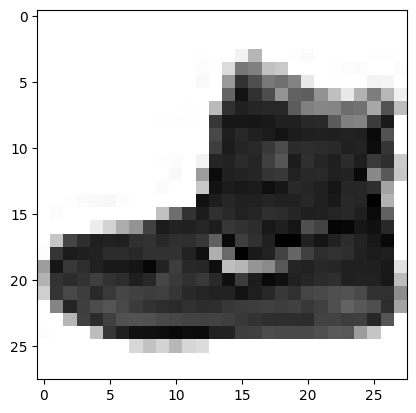

In [46]:
import matplotlib.pyplot as plt
import numpy as np
print(y[0])
plt.imshow(np.reshape(X[0],[28,28]),cmap='binary')
plt.show()

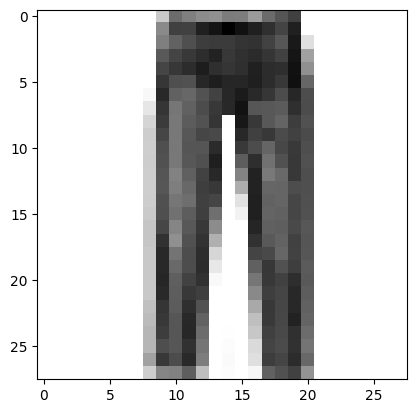

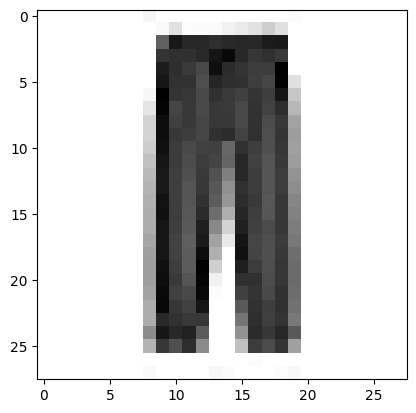

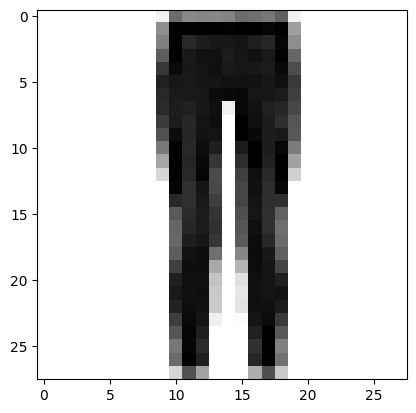

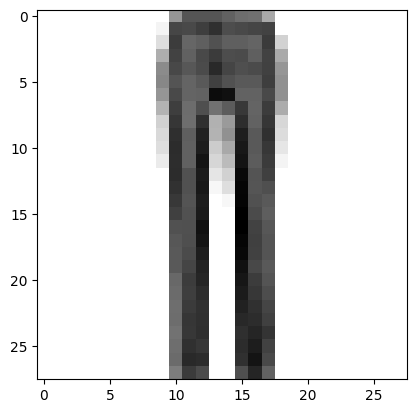

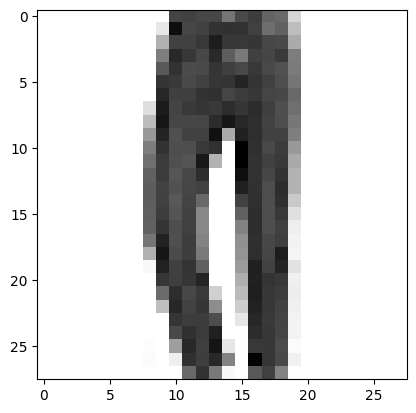

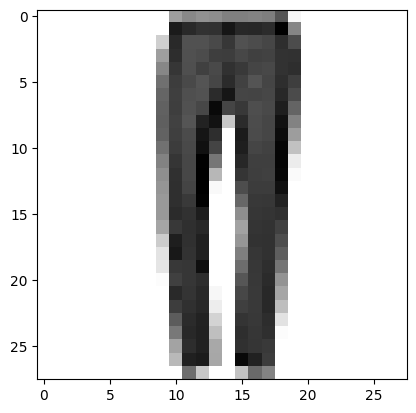

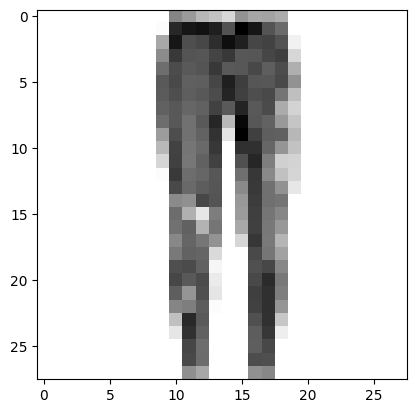

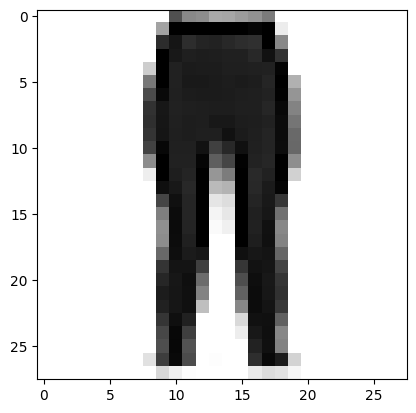

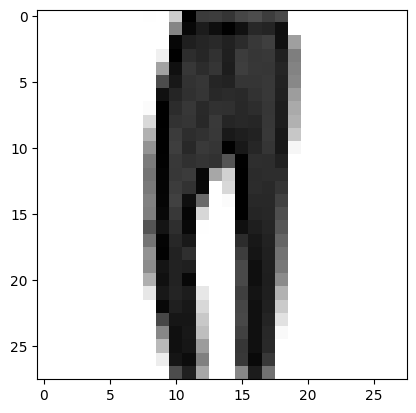

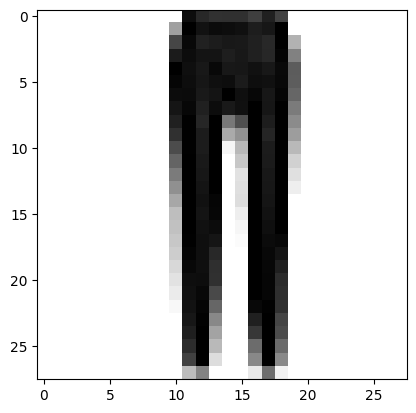

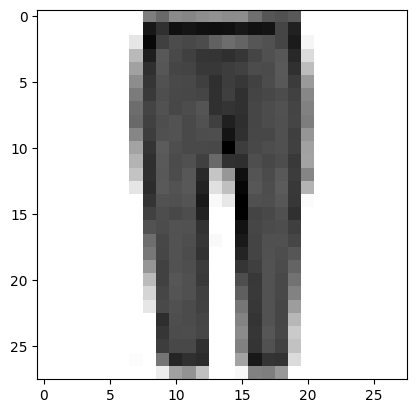

In [48]:
for elm in range(0,100):
  if y[elm] == 1:
    plt.imshow(np.reshape(X[elm],[28,28]),cmap='binary')
    plt.show()

In [52]:
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)
X_train, X_Val, y_train, y_Val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

pipe = make_pipeline(PCA(.97), LogisticRegression())
pipe.fit(X_train, y_train)
#This spends a lot of time thinking

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('pca', PCA(n_components=0.97)),
                ('logisticregression', LogisticRegression())])

In [53]:
print("Val pred vs real:\n", np.array([pipe.predict(X_Val), y_Val]).T[:10])
print("Val acc:", pipe.score(X_Val, y_Val))
print("Test acc:", pipe.score(X_test, y_test))

Val pred vs real:
 [[7 7]
 [4 4]
 [5 5]
 [0 0]
 [0 0]
 [7 7]
 [3 3]
 [5 5]
 [5 5]
 [7 7]]
Val acc: 0.8489118303571429
Test acc: 0.8418571428571429


In [54]:
pipe = make_pipeline(
    StandardScaler(),
    PCA(0.97),
    LogisticRegression(max_iter=1000)
)
pipe.fit(X_train, y_train)
#this spends a looooot of time

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('pca', PCA(n_components=0.97)),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [55]:
print("Val pred vs real:\n", np.array([pipe.predict(X_Val), y_Val]).T[:10])
print("Val acc:", pipe.score(X_Val, y_Val))
print("Test acc:", pipe.score(X_test, y_test))

Val pred vs real:
 [[7 7]
 [4 4]
 [5 5]
 [0 0]
 [0 0]
 [7 7]
 [3 3]
 [5 5]
 [5 5]
 [7 7]]
Val acc: 0.8486328125
Test acc: 0.8407142857142857
